# Autoria, revisão e promoção de Cedar

25 minutos • Referência P2

[Objetivos e sequência de aprendizagem](../docs/jornada.md).
Execute com o kernel Python de `.venv`.

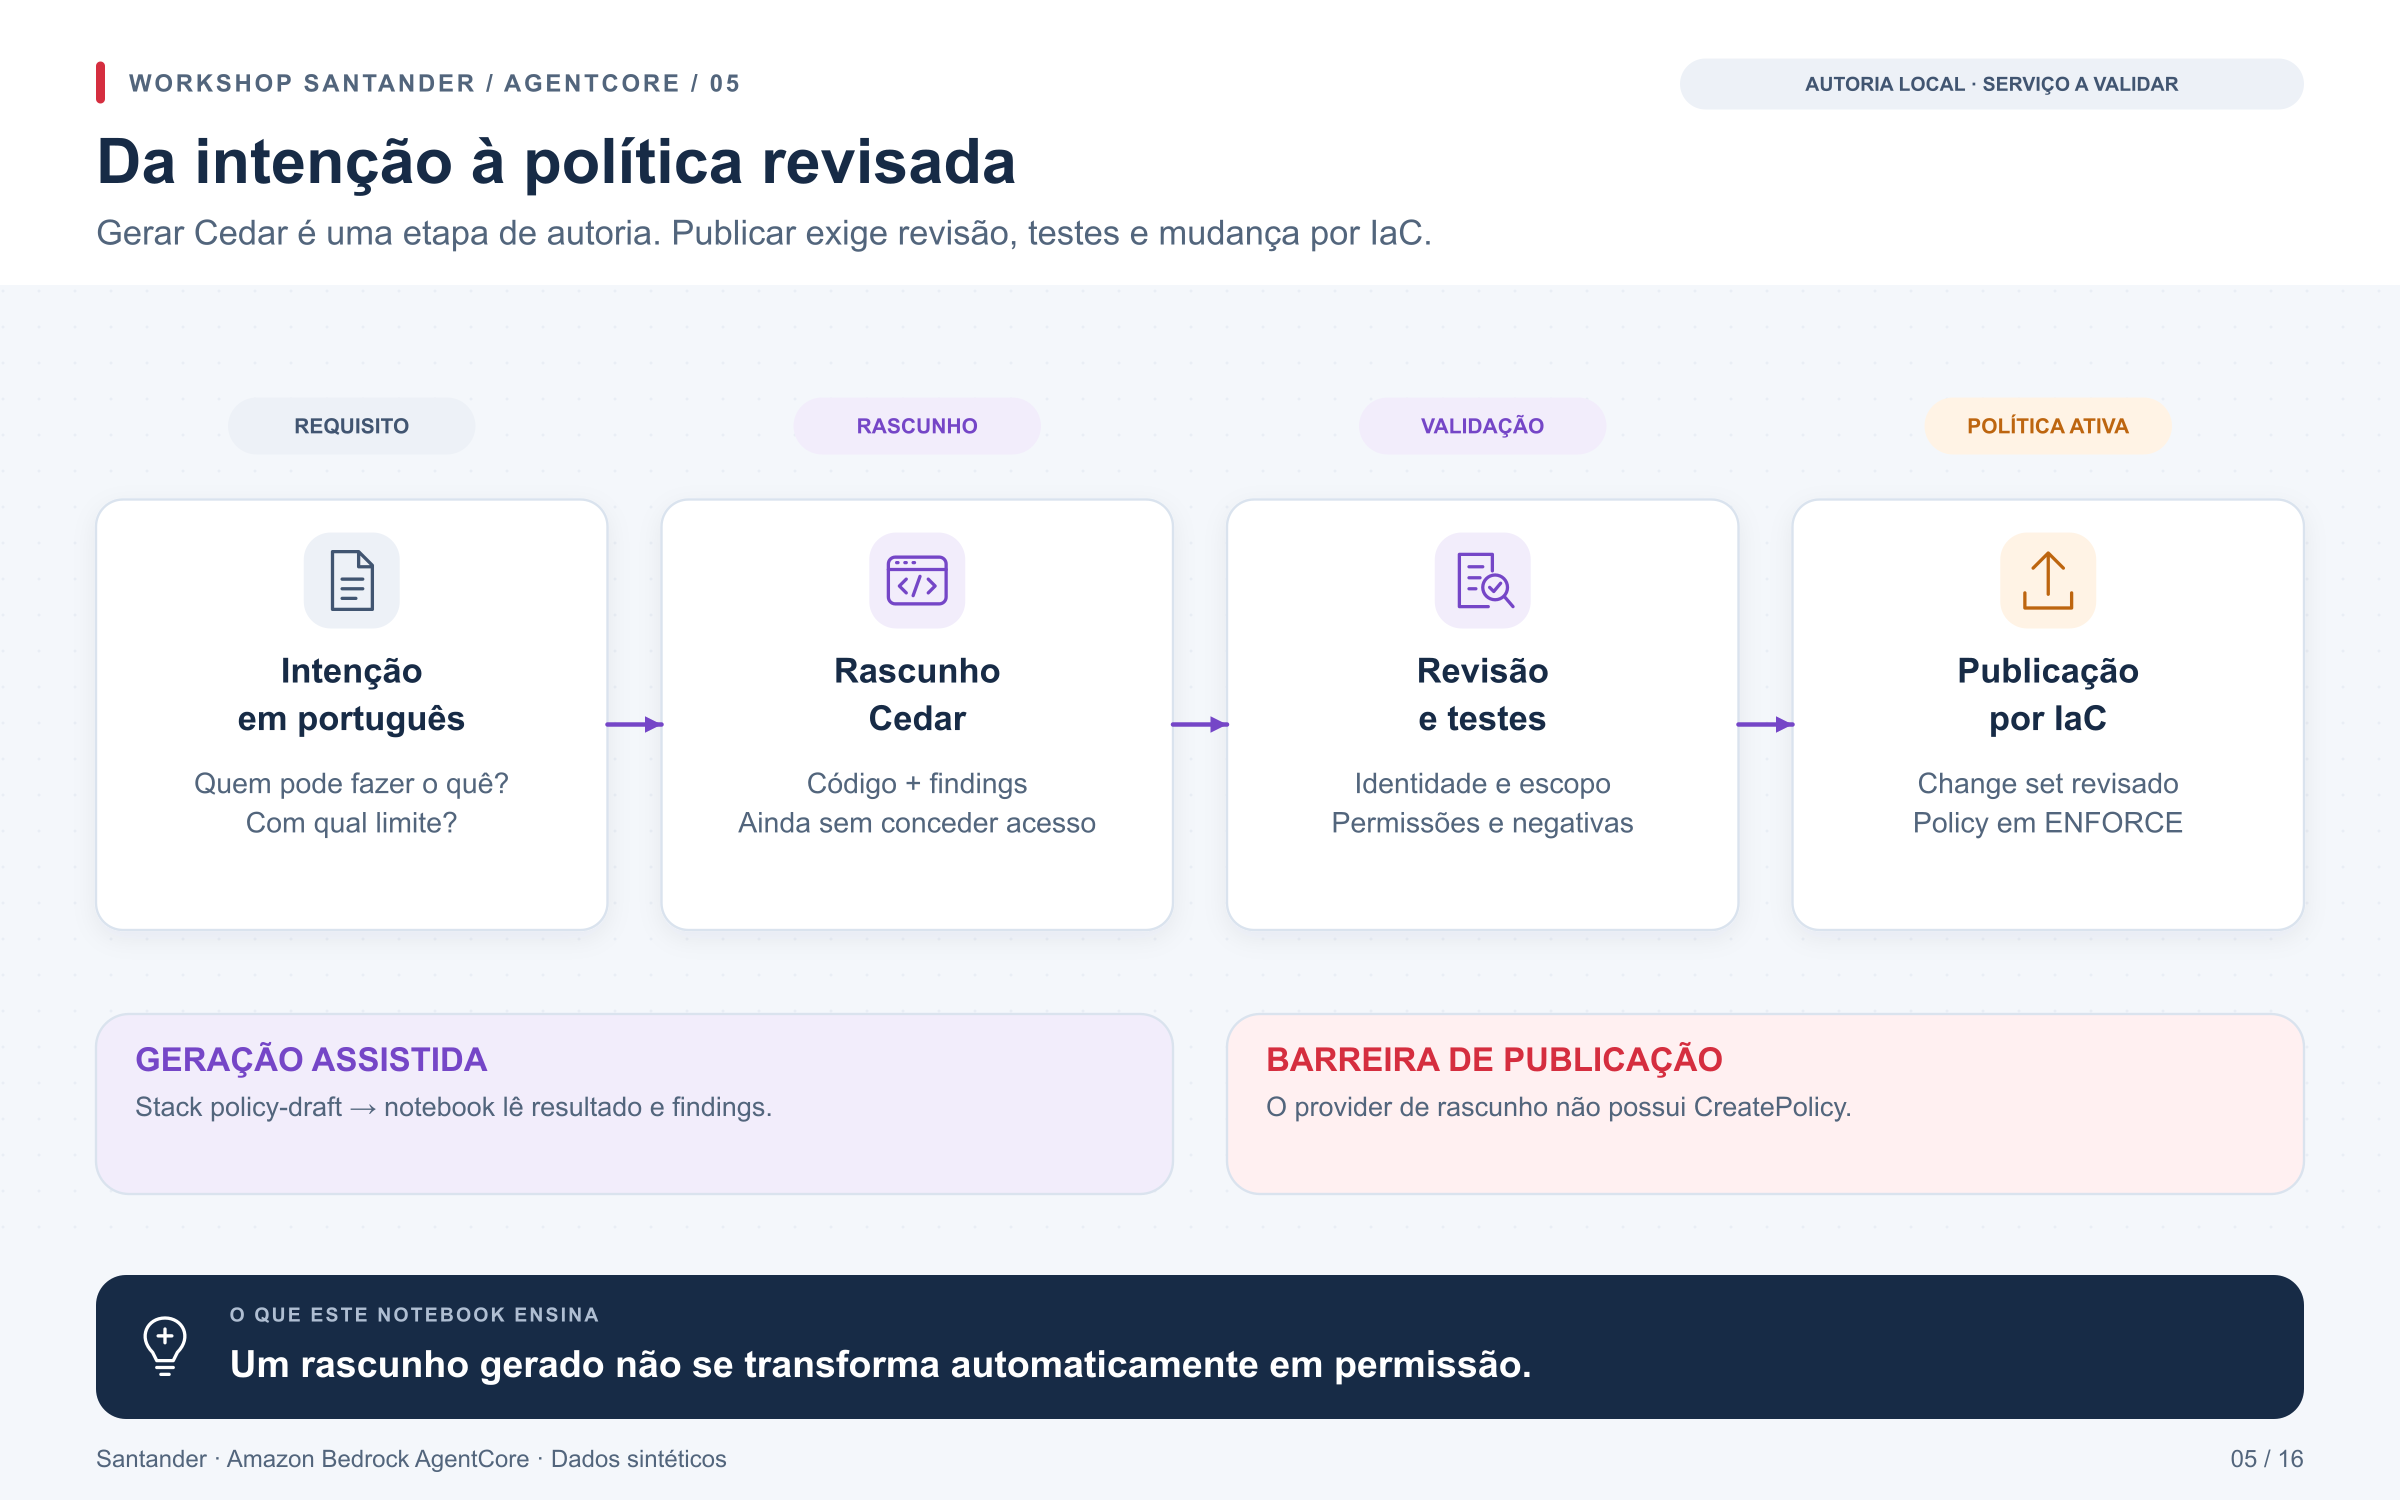

**Objetivo visual:** Conferir se o Cedar representa a intenção e se os casos permitidos e negados continuam corretos.

[Abrir PNG](../docs/diagramas/png/05_policy_autoria.png) · [SVG editável](../docs/diagramas/svg/05_policy_autoria.svg) · [Galeria dos notebooks](../docs/diagramas/index.html)

**Etapa 6 de 17 na jornada.** [Jornada completa](../docs/jornada.md) · [Anterior: Autorização Cedar](04_policy_cedar.ipynb) · [Próximo: Governança do catálogo](06_registry_governanca.ipynb)

## Conceitos para acompanhar este laboratório

**Autoria**, **validação** e **publicação** são etapas diferentes.
Descrever a intenção em linguagem natural produz um candidato a política;
não concede acesso por si só. Os **findings** são apontamentos do serviço
sobre o candidato e precisam ser examinados junto com o comportamento desejado.

Este notebook tem dois caminhos: geração determinística de Cedar a partir
de [policy.py](../src/santander_demo/policy.py), e leitura de um rascunho
gerado previamente pelo stack `policy-draft`. Nenhum deles publica uma
política por esta célula.

Um **change set** mostra as alterações propostas ao CloudFormation antes
de aplicá-las. `FAIL_ON_ANY_FINDINGS` é uma propriedade de validação dos
recursos de Policy no template; revise-a junto com o change set.
**Retain** preserva o recurso ao excluir o stack: não significa que o
rascunho foi aprovado ou se tornou uma política ativa.

**Documentação oficial para aprofundar:**

* [Validação de políticas geradas](https://docs.aws.amazon.com/bedrock-agentcore/latest/devguide/policy-generation-validation.html)
* [Guia de autoria de Policy](https://docs.aws.amazon.com/bedrock-agentcore/latest/devguide/policy-authoring-guide.html)
* [CloudFormation: revisão de change sets](https://docs.aws.amazon.com/AWSCloudFormation/latest/UserGuide/using-cfn-updating-stacks-changesets.html)

As explicações estão em português; nomes de APIs, claims e campos permanecem como aparecem no código. As páginas oficiais podem estar em inglês.

### Preparar o ambiente deste notebook

Vamos importar os componentes do workshop, localizar a pasta do projeto e ler
`WORKSHOP_MODE`, cujo padrão é `local`. A instância `lab` reúne o emissor de
tokens de teste, o catálogo em memória, as políticas Cedar e o registro de
evidências que serão usados nas próximas células.

Se o modo for `aws`, também carregaremos `config/local.json` e inicializaremos
o cliente do ambiente configurado. Ao final, a mensagem mostrará o modo ativo;
`LOCAL_SIMULATION` indica que os resultados locais não comprovam a integração
com AWS ou Entra. Reexecutar esta célula reinicia o estado local do laboratório.

In [ ]:
import os
from pathlib import Path
from santander_demo.local import Workshop
from santander_demo.contracts import CLIENTE, DemoError

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
MODE = os.environ.get("WORKSHOP_MODE", "local")
assert MODE in {"local", "aws"}, "WORKSHOP_MODE deve ser local ou aws"
lab = Workshop()
cloud = None
if MODE == "aws":
    from santander_demo.config import Environment
    from santander_demo.cloud import CloudWorkshop
    config = Environment.load(ROOT / "config/local.json")
    cloud = CloudWorkshop(config)
print("LOCAL_SIMULATION — nenhuma prova de AWS/Entra" if MODE == "local" else "AWS — integração real")

Intenção: “usuários habilitados a Riscos, usando uma aplicação autorizada,
consultam até 50 registros do Gateway do workshop”.

A autoria determinística roda localmente. Para geração assistida pelo serviço,
o stack `policy-draft` recebe o texto em `RawText` e cria um rascunho via IaC.
O notebook apenas lê esse resultado. O provider não possui permissão para
publicar políticas. A API não expõe exclusão do histórico de geração; por isso
o template marca o rascunho como Retain, sem confundi-lo com uma policy ativa.

### Inspecionar a regra de Riscos e suas verificações locais

Vamos obter a regra de `riscos___consultar_risco` e confirmar no texto
a presença do limite de cinquenta registros e da checagem da tag
`oid`. Também executaremos a matriz local e verificaremos que ela
contém os doze cenários previstos.

Se todas as asserções passarem, a célula imprimirá o Cedar para
revisão. Trata-se de geração determinística a partir da fonte do
projeto; esta etapa não solicita geração em linguagem natural ao serviço.

In [ ]:
from santander_demo.policy import statements
cedar = statements(lab.policy)["riscos___consultar_risco"]
assert "context.input.max_registros <= 50" in cedar
assert 'principal.hasTag("oid")' in cedar
assert len(lab.policy_matrix()) == 12
print(cedar)

### Ler um rascunho gerado anteriormente

Vamos ler `POLICY_GENERATION_ID` para identificar um rascunho já
criado pelo stack de autoria. Com esse identificador e o modo AWS
ativos, consultaremos os assets gerados e exibiremos suas definições
Cedar e findings, que são os apontamentos retornados para revisão.

O helper exige que a geração esteja concluída e entrega o resultado
para revisão, sem publicá-lo. Sem o identificador ou no modo local,
a saída será `managed_generation: NOT_RUN`; nenhuma geração será iniciada.

In [ ]:
generation_id = os.environ.get("POLICY_GENERATION_ID")
if MODE == "aws" and generation_id:
    draft = cloud.policy_draft(generation_id)
    assert draft["review_required"] and not draft["published"]
    for asset in draft["assets"]:
        print({"definition": asset["definition"], "findings": asset.get("findings", [])})
else:
    print({"managed_generation": "NOT_RUN", "local_cedar": "VALIDATED_LOCAL",
           "human_review": "PENDING"})

**Revisão em dupla:**
1. Tenant, OID e aplicação vêm de claims assinadas?
2. A ação e o recurso são exatos?
3. O limite está no mesmo `permit` das condições de identidade?
4. Há testes de usuário, chamador, claim ausente e nomes semelhantes?
5. Os recursos de Policy no template usam `FAIL_ON_ANY_FINDINGS`?

Altere a fonte em `src/santander_demo/policy.py`, gere os templates, execute os
testes e revise o change set antes do deploy pelo pipeline do projeto.

## Limpeza — recursos do laboratório

Os notebooks **00–06, 08, 10 e 13 compartilham o ambiente**. Remova os stacks somente
ao encerrar toda a trilha, depois de salvar as evidências.

1. Atualize `origin` com `EnableRuntime=false` pelo `scripts/deploy.py`.
2. Remova `registry`; preserve o output de `policy-draft`, se utilizado,
   antes de remover seu stack. O histórico de geração usa `Retain`.
3. Atualize `hub` com `EnableFraud=false` pelo `scripts/deploy.py`.
4. Remova `fraud-runtime`, depois `hub` e, por último, `origin`.
5. Remova os stacks `bootstrap` somente após revisar os artefatos retidos.

Para cada remoção, use o template correspondente e o **nome real do stack**
implantado. Os nomes de template acima não determinam os nomes dos stacks.
Buckets usam `Retain`; aplicações e segredos Entra seguem o Terraform que os
gerencia. O notebook 13 não é proprietário do workspace, warehouse ou grants
Databricks. Consulte o [runbook da trilha](../docs/deploy.md#9-limpeza).

**Na próxima célula**, `CLEANUP_TARGET=None` manterá a remoção desativada e
imprimirá `cloud_cleanup: NOT_RUN`. Para revisar um stack real, preencha o
alvo indicado no comentário e mantenha `CLEANUP_EXECUTE=False`. O script
`scripts/cleanup.py` consultará STS e CloudFormation, exigirá correspondência
exata entre template implantado e fonte local e mostrará o ARN, as retenções
declaradas e eventuais bloqueios. Essa preparação faz somente leituras.

Após revisar o plano e a ordem acima, copie seu ARN para
`CLEANUP_CONFIRM_STACK_ID` e habilite `CLEANUP_EXECUTE` para remover **esse
stack** pelo wrapper IaC. O script aguarda a exclusão pelo CloudFormation,
respeita `Retain` e não desativa proteções. Falhas devem ser resolvidas no
IaC. A execução padrão deste notebook não remove recursos em nuvem.

In [ ]:
import subprocess as _cleanup_subprocess
import sys as _cleanup_sys

# Preencha somente para um stack do laboratório, após encerrar a trilha:
# {"template": "TEMPLATE", "stack": "NOME_REAL", "profile": "PERFIL",
#   "account": "ID_DA_CONTA", "region": "REGIAO"}
CLEANUP_TARGET = None
CLEANUP_EXECUTE = False
CLEANUP_CONFIRM_STACK_ID = ""

if CLEANUP_TARGET is None:
    print({"cloud_cleanup": "NOT_RUN", "reason": "Nenhum stack selecionado"})
else:
    assert set(CLEANUP_TARGET) == {"template", "stack", "profile", "account", "region"}
    _cleanup_command = [
        _cleanup_sys.executable, str(ROOT / "scripts/cleanup.py"),
        "--scenario", "workshop",
    ]
    for _cleanup_key, _cleanup_value in CLEANUP_TARGET.items():
        _cleanup_command.extend(["--" + _cleanup_key, _cleanup_value])
    if CLEANUP_EXECUTE:
        assert CLEANUP_CONFIRM_STACK_ID, "Revise o plano e informe o ARN exato do stack"
        _cleanup_command.extend(["--execute", "--confirm-stack-id", CLEANUP_CONFIRM_STACK_ID])
    _cleanup_subprocess.run(_cleanup_command, cwd=ROOT, check=True)

### Limpeza — estado local do notebook

Vamos remover as variáveis de dados, tokens, clientes e configuração criadas
por este exercício. As sessões MCP abertas com `async with` já foram encerradas
ao sair de seus blocos; o cliente de controle de `cloud`, quando presente,
também será fechado. A célula verificará que os nomes listados deixaram
de existir e exibirá `cleanup_local: PASS`; ela pode ser repetida.

Os notebooks, diagramas, templates e arquivos de evidências serão preservados.
Esta limpeza remove referências do namespace; não revoga tokens nem apaga
outputs ou todas as cópias que possam existir na memória do processo.
Após salvar as evidências, limpe as saídas e encerre o kernel para terminar
a sessão. Para repetir o laboratório, recomece pela preparação do ambiente.

In [ ]:
import json as _cleanup_json

if globals().get("cloud") is not None:
    cloud.control.close()
_cleanup_names = ['CLEANUP_CONFIRM_STACK_ID', 'CLEANUP_EXECUTE', 'CLEANUP_TARGET', 'MODE',
 '_cleanup_command', '_cleanup_key', '_cleanup_subprocess', '_cleanup_sys',
 '_cleanup_value', 'asset', 'cedar', 'cloud', 'config', 'draft', 'generation_id',
 'identity', 'lab', 'token']
_cleanup_removed = [name for name in _cleanup_names if name in globals()]
for _cleanup_name in _cleanup_names:
    globals().pop(_cleanup_name, None)
assert not any(name in globals() for name in _cleanup_names)
print(_cleanup_json.dumps({
    "cleanup_local": "PASS",
    "removed_variables": len(_cleanup_removed),
    "files": "PRESERVED",
}, ensure_ascii=False))
del _cleanup_name, _cleanup_names, _cleanup_removed, _cleanup_json